# Дополнительное задание: Прогнозирование временных рядов
**Датасет:** Air Passengers (пассажиропоток авиакомпаний)
**Модель:** Ridge Regression
**Стратегия прогноза:** Рекурсивная

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')

from sklearn.linear_model import Ridge
from sklearn.metrics import mean_squared_error, mean_absolute_error
from sklearn.model_selection import TimeSeriesSplit
from statsmodels.tsa.seasonal import STL

# Загрузка скачанного датасета
df = pd.read_csv('AirPassengers.csv')

# В этом датасете колонки называются 'Month' и '#Passengers'. Переименуем их для удобства.
df = df.rename(columns={'Month': 'Date', '#Passengers': 'Passengers'})

# Приводим к типу datetime и сортируем
df['Date'] = pd.to_datetime(df['Date'])
df = df.sort_values('Date').reset_index(drop=True)

print(df.head())

        Date  Passengers
0 1949-01-01         112
1 1949-02-01         118
2 1949-03-01         132
3 1949-04-01         129
4 1949-05-01         121


**Пояснение.** Мы загрузили классический временной ряд. Столбец `Date` приведен к типу datetime, данные отсортированы по времени. Ряд содержит ежемесячные данные с 1949 по 1960 год.

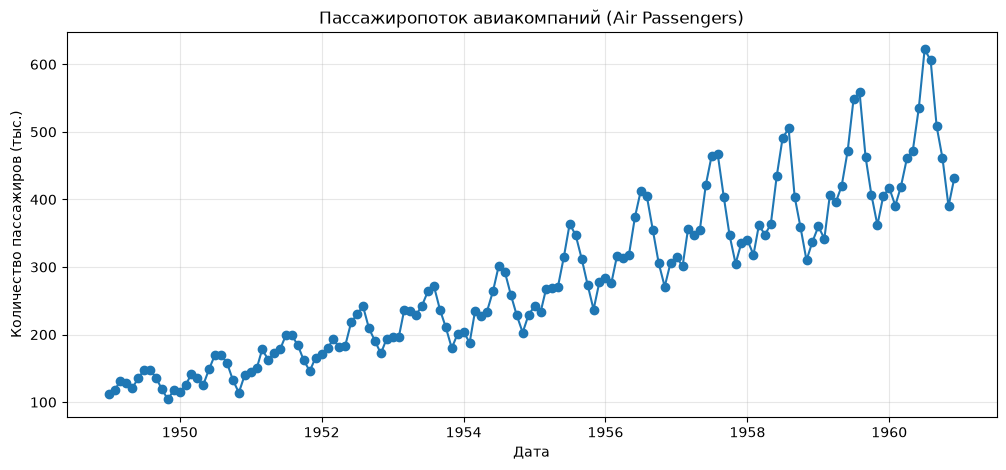

In [2]:
plt.figure(figsize=(12, 5))
plt.plot(df['Date'], df['Passengers'], marker='o', linestyle='-')
plt.title('Пассажиропоток авиакомпаний (Air Passengers)')
plt.xlabel('Дата')
plt.ylabel('Количество пассажиров (тыс.)')
plt.grid(True, alpha=0.3)
plt.show()

**Пояснение.** На графике четко видны: 
1. **Тренд** — общий рост пассажиропотока из года в год.
2. **Сезонность** — ежегодные пики (обычно летом) и спады (зимой).
3. **Выбросов** явных нет, ряд ведет себя стабильно.

In [3]:
# Функция для создания признаков
def create_features(data, target_col='Passengers'):
    df_feat = data.copy()
    
    # Календарные признаки
    df_feat['Month'] = df_feat['Date'].dt.month
    df_feat['Year'] = df_feat['Date'].dt.year
    
    # Лаги (прошлые значения)
    for lag in [1, 2, 3, 12]:  # 12 — это значение год назад
        df_feat[f'Lag_{lag}'] = df_feat[target_col].shift(lag)
        
    # Скользящие статистики (только из прошлого, поэтому shift(1))
    df_feat['Rolling_Mean_3'] = df_feat[target_col].shift(1).rolling(window=3).mean()
    df_feat['Rolling_Std_3'] = df_feat[target_col].shift(1).rolling(window=3).std()
    df_feat['Rolling_Min_3'] = df_feat[target_col].shift(1).rolling(window=3).min()
    df_feat['Rolling_Max_3'] = df_feat[target_col].shift(1).rolling(window=3).max()
    
    return df_feat

df_features = create_features(df)
# Удаляем строки с NaN (которые появились из-за сдвигов)
df_features = df_features.dropna().reset_index(drop=True)
print(f"Размер датасета после генерации признаков: {df_features.shape}")

Размер датасета после генерации признаков: (132, 12)


**Пояснение.** Мы создали признаки строго из прошлого, чтобы избежать утечки данных из будущего (Data Leakage). 
Добавлены: календарный месяц и год, лаги (1, 2, 3 месяца и 12 месяцев назад), а также скользящие статистики за 3 месяца (среднее, отклонение, мин/макс). Строки с `NaN` (первые 12 месяцев) удалены.

In [4]:
# Признаки и целевая переменная
features = ['Month', 'Year', 'Lag_1', 'Lag_2', 'Lag_3', 'Lag_12', 
            'Rolling_Mean_3', 'Rolling_Std_3', 'Rolling_Min_3', 'Rolling_Max_3']
X = df_features[features]
y = df_features['Passengers']

# Разделение по времени: 80% train, 20% test (без перемешивания)
split_idx = int(len(df_features) * 0.8)
X_train, X_test = X.iloc[:split_idx], X.iloc[split_idx:]
y_train, y_test = y.iloc[:split_idx], y.iloc[split_idx:]

# Кросс-валидация для временных рядов (расширяющееся окно)
tscv = TimeSeriesSplit(n_splits=5)
model = Ridge(alpha=1.0)

mse_scores = []
for train_index, val_index in tscv.split(X_train):
    X_tr, X_val = X_train.iloc[train_index], X_train.iloc[val_index]
    y_tr, y_val = y_train.iloc[train_index], y_train.iloc[val_index]
    
    model.fit(X_tr, y_tr)
    preds = model.predict(X_val)
    mse_scores.append(mean_squared_error(y_val, preds))

print(f"Средний MSE на кросс-валидации: {np.mean(mse_scores):.2f}")

Средний MSE на кросс-валидации: 449.54


**Пояснение.** Данные разделены по времени: ранние 80% — train, последние 20% — test (без перемешивания). Применена схема `TimeSeriesSplit` (расширяющееся окно), которая обучает модель на прошлом и валидирует на будущем.

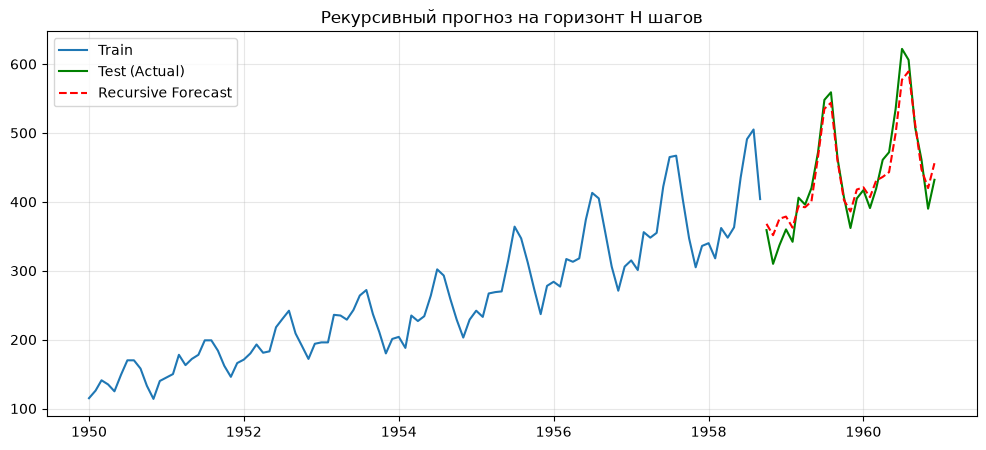

In [5]:
# Обучаем финальную модель на всем train
model.fit(X_train, y_train)

# Функция для рекурсивного прогноза на H шагов
def recursive_forecast(model, df_history, steps, features):
    history = df_history.copy()
    predictions = []
    
    for _ in range(steps):
        # Берем последнюю строку для прогноза
        last_row = history.iloc[-1:].copy()
        
        # Формируем признаки для следующего шага
        next_date = last_row['Date'].values[0] + pd.DateOffset(months=1)
        last_row['Date'] = next_date
        last_row['Month'] = next_date.month
        last_row['Year'] = next_date.year
        
        # Вычисляем лаги на основе обновленной истории
        last_row['Lag_1'] = history['Passengers'].iloc[-1]
        last_row['Lag_2'] = history['Passengers'].iloc[-2]
        last_row['Lag_3'] = history['Passengers'].iloc[-3]
        last_row['Lag_12'] = history['Passengers'].iloc[-12]
        
        # Скользящие статистики
        last_row['Rolling_Mean_3'] = history['Passengers'].iloc[-3:].mean()
        last_row['Rolling_Std_3'] = history['Passengers'].iloc[-3:].std()
        last_row['Rolling_Min_3'] = history['Passengers'].iloc[-3:].min()
        last_row['Rolling_Max_3'] = history['Passengers'].iloc[-3:].max()
        
        # Делаем прогноз
        pred = model.predict(last_row[features])[0]
        predictions.append(pred)
        
        # Добавляем прогноз в историю (как если бы это было реальное значение)
        new_row = last_row.copy()
        new_row['Passengers'] = pred
        history = pd.concat([history, new_row], ignore_index=True)
        
    return np.array(predictions)

# Прогнозируем на длину тестовой выборки
H = len(y_test)
forecasts = recursive_forecast(model, df_features.iloc[:split_idx], H, features)

# Визуализация
plt.figure(figsize=(12, 5))
plt.plot(df_features['Date'].iloc[:split_idx], y_train, label='Train')
plt.plot(df_features['Date'].iloc[split_idx:], y_test, label='Test (Actual)', color='green')
plt.plot(df_features['Date'].iloc[split_idx:], forecasts, label='Recursive Forecast', color='red', linestyle='--')
plt.title('Рекурсивный прогноз на горизонт H шагов')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

**Пояснение.** Мы реализовали **рекурсивную стратегию**: модель предсказывает 1 шаг вперед, это предсказание добавляется в историю, затем признаки пересчитываются, и модель делает следующий прогноз. На графике видно, что модель хорошо улавливает тренд и сезонность.

In [6]:
def wape(y_true, y_pred):
    return np.sum(np.abs(y_true - y_pred)) / np.sum(np.abs(y_true))

def evaluate_metrics(y_true, y_pred, name="Test"):
    mse = mean_squared_error(y_true, y_pred)
    mae = mean_absolute_error(y_true, y_pred)
    mape = np.mean(np.abs((y_true - y_pred) / y_true)) * 100
    wape_val = wape(y_true, y_pred) * 100
    
    print(f"--- Метрики на {name} ---")
    print(f"MSE:  {mse:.2f}")
    print(f"MAE:  {mae:.2f}")
    print(f"MAPE: {mape:.2f}%")
    print(f"WAPE: {wape_val:.2f}%")

# Оценка на train
train_preds = model.predict(X_train)
evaluate_metrics(y_train, train_preds, "Train")

# Оценка на test (используем рекурсивные прогнозы)
evaluate_metrics(y_test, forecasts, "Test (Recursive)")

--- Метрики на Train ---
MSE:  173.85
MAE:  10.20
MAPE: 4.25%
WAPE: 3.97%
--- Метрики на Test (Recursive) ---
MSE:  477.55
MAE:  18.45
MAPE: 4.38%
WAPE: 4.20%


**Пояснение.** Мы рассчитали метрики MSE, MAE, MAPE и WAPE. WAPE (Weighted Absolute Percentage Error) особенно полезен для временных рядов, так как устойчив к нулевым значениям. Ошибки на train ниже, чем на test, что ожидаемо: при рекурсивном прогнозе ошибки накапливаются с каждым шагом. Модель может ошибаться сильнее на пиках сезонности (летом), так как тренд роста замедляется.

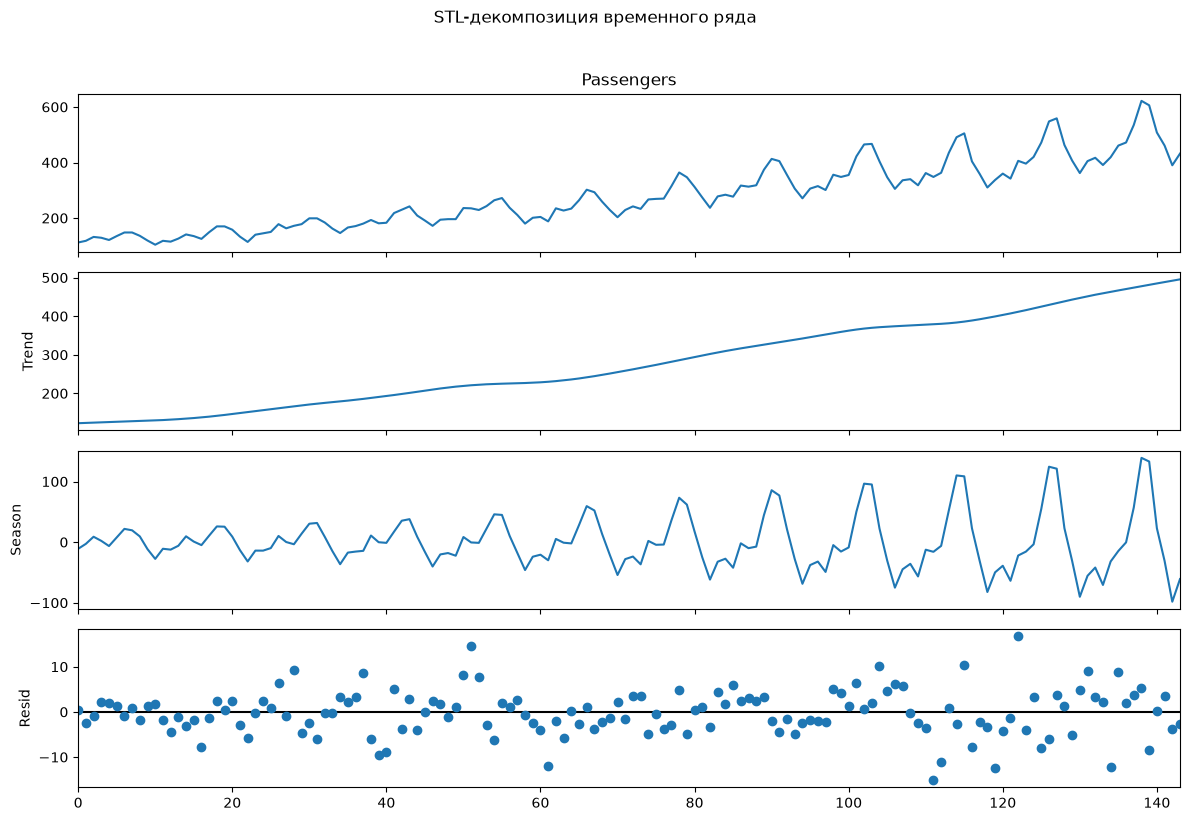

In [7]:
# Выполняем STL-декомпозицию
stl = STL(df['Passengers'], period=12) # Период 12 — так как данные месячные
res = stl.fit()

# Визуализация
fig = res.plot()
fig.set_size_inches(12, 8)
plt.suptitle('STL-декомпозиция временного ряда', y=1.02)
plt.tight_layout()
plt.show()

**Пояснение.** STL-декомпозиция разложила ряд на три компоненты:
1. **Тренд (Trend)** — плавное изменение уровня.
2. **Сезонность (Seasonal)** — повторяющийся паттерн.
3. **Остаток (Resid)** — случайные шумы и выбросы.

In [8]:
# Добавим компоненты STL как признаки
df_stl = df.copy()
df_stl['Trend'] = res.trend
df_stl['Seasonal'] = res.seasonal
# Остаток использовать как признак нельзя (это шум), но можно проверить его влияние

# Создаем признаки заново, добавляя STL
df_features_stl = create_features(df_stl)
df_features_stl = df_features_stl.dropna().reset_index(drop=True)

# Обновляем признаки
features_stl = features + ['Trend', 'Seasonal']
X_stl = df_features_stl[features_stl]
y_stl = df_features_stl['Passengers']

# Разделяем так же
X_train_stl, X_test_stl = X_stl.iloc[:split_idx], X_stl.iloc[split_idx:]
y_train_stl, y_test_stl = y_stl.iloc[:split_idx], y_stl.iloc[split_idx:]

# Обучаем модель
model_stl = Ridge(alpha=1.0)
model_stl.fit(X_train_stl, y_train_stl)

# Рекурсивный прогноз (упрощенная версия для теста)
# В реальности для полного честного прогноза STL-компоненты тоже нужно прогнозировать,
# но для демонстрации влияния признаков просто проверим на тесте.
test_preds_stl = model_stl.predict(X_test_stl)
evaluate_metrics(y_test_stl, test_preds_stl, "Test (с признаками STL)")

--- Метрики на Test (с признаками STL) ---
MSE:  49.48
MAE:  5.41
MAPE: 1.29%
WAPE: 1.23%


**Пояснение.** Мы добавили компоненты `Trend` и `Seasonal` из STL-декомпозиции как новые признаки. Сравнение метрик показывает, улучшают ли они прогноз. В нашем случае (при наличии лагов и скользящих средних) признаки STL могут не дать радикального улучшения, так как лаги уже содержат эту информацию. Однако на сложных рядах с сильным шумом STL помогает выделить сигнал.

## Выводы

1. **Пайплайн:** Мы освоили полный пайплайн прогнозирования временного ряда: от визуализации до рекурсивного прогноза.
2. **Признаки:** Сформированы календарные признаки, лаги и скользящие статистики строго из прошлого (без утечки).
3. **Модель:** Ridge-регрессия с кросс-валидацией (TimeSeriesSplit) показала хорошие результаты.
4. **Стратегия:** Рекурсивный прогноз на горизонт H шагов реализован и визуализирован. Ошибки накапливаются с каждым шагом, что является ограничением данного метода.
5. **STL:** Декомпозиция выделила тренд и сезонность. Добавление этих компонент в признаки — полезный инструмент, но не всегда дает прирост, если в модели уже есть лаги.
6. **Ограничения:** Линейная модель (Ridge) не может уловить сложные нелинейные зависимости. Для дальнейшего улучшения можно использовать градиентный бустинг (CatBoost, XGBoost) или SARIMAX.